# EDA — JobMatch

## Présentation
Notre projet JobMatch étudie les offres d’emploi et les compétences demandées afin de mieux comprendre le marché de l’emploi.

**Source :** Job Market Intelligence 2024 - Skills Global Dataset, Kaggle — [https://www.kaggle.com/datasets/thedarkvenom/job-market-intelligence-2024-skills-global-dataset].

Chaque ligne de `fact_job_postings` représente une offre d’emploi. Les compétences associées aux offres sont enregistrées dans `bridge_job_skills`.

Dans cette EDA, mon objectif est de décrire le contenu du dataset, de vérifier si les données sont suffisamment propres pour être exploitées, puis d’identifier quelques tendances simples sur les métiers, les salaires, les compétences et les pays. L’idée n’est pas de prouver une vérité générale sur tout le marché de l’emploi, mais de comprendre ce que montrent précisément ces données.

Tout au long du notebook, j’essaie donc de répondre à quatre questions : qu’est-ce que j’ai dans ce dataset, est-ce que ces données sont cohérentes, que peut-on observer à l’intérieur du fichier, et enfin quelles sont les limites à garder en tête avant d’interpréter les résultats.

## 1. Qu’ai-je ?

**Dataset :** Job Market Intelligence 2024 - Skills Global Dataset  
**Source Kaggle :** https://www.kaggle.com/datasets/thedarkvenom/job-market-intelligence-2024-skills-global-dataset  
**Une ligne de `fact_job_postings` représente :** une offre d’emploi.

L’objectif de cette analyse est de comprendre la structure du marché de l’emploi dans ce dataset : quels métiers sont les plus représentés, quelles compétences sont les plus demandées, comment les salaires et les modes de travail varient selon l’expérience, et quelles limites méthodologiques doivent être prises en compte avant de tirer des conclusions sur le marché réel.

Dans cette première partie, je présente les fichiers disponibles, la taille des tables, les colonnes, les types de variables et quelques exemples de lignes. Cette étape est importante, car avant de faire des graphiques ou des comparaisons, il faut d’abord comprendre précisément ce que contient chaque table et à quoi elle sert.

## 2. Est-ce propre ?

Dans cette partie, je vérifie les valeurs manquantes, les doublons, les catégories, les valeurs numériques, les dates et les liens entre les offres et les compétences. Le but est de m’assurer que les analyses suivantes ne reposent pas sur des données incohérentes ou incomplètes.

## 3. Que se passe-t-il ?

Dans cette partie, j’analyse les métiers, les compétences, les salaires selon l’expérience, les modes de travail et la répartition des offres par pays. Chaque sous-partie correspond à une question simple, avec une méthode de lecture claire et une interprétation prudente des résultats.

Pour chaque analyse, j’explique la question étudiée, le choix de la méthode et ce que montrent les résultats. J’essaie aussi de distinguer ce que l’on peut réellement conclure de ce qui demanderait une étude plus approfondie.

## 4. Qu’est-ce qui manque ?

Dans cette partie, je note les limites du dataset et ce qu’il ne permet pas d’étudier. Cette étape est importante, car une bonne EDA ne consiste pas seulement à décrire des résultats, mais aussi à reconnaître ce que les données ne permettent pas de dire.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import sys
from IPython.display import display

project_root = Path.cwd() if (Path.cwd() / "data" / "archive").exists() else Path.cwd().parent
sys.path.insert(0, str(project_root))
from src.analysis import group_percentages, skill_pairs, skill_prevalence

data_dir = project_root / "data" / "archive"

offres = pd.read_csv(data_dir / "fact_job_postings.csv")
competences_offres = pd.read_csv(data_dir / "bridge_job_skills.csv")
liste_competences = pd.read_csv(data_dir / "dim_skill.csv")
entreprises = pd.read_csv(data_dir / "dim_company.csv")
pays = pd.read_csv(data_dir / "dim_country.csv")
plateformes = pd.read_csv(data_dir / "dim_platform.csv")

In [2]:
tables = {
    "offres": offres,
    "compétences par offre": competences_offres,
    "liste des compétences": liste_competences,
    "entreprises": entreprises,
    "pays": pays,
    "plateformes": plateformes,
}

for nom, table in tables.items():
    print(nom, table.shape)

offres (55000, 13)
compétences par offre (247398, 2)
liste des compétences (26, 1)
entreprises (20, 1)
pays (13, 2)
plateformes (6, 1)


## Structure des offres

Question : quelles variables sont disponibles, et sous quels types ?

J’inspecte la table des offres avant de choisir mes analyses. Cette étape sert à identifier quelles colonnes décrivent des catégories, lesquelles contiennent des valeurs numériques, et lesquelles devront être manipulées avec prudence avant d’être interprétées.

Autrement dit, avant de répondre à des questions sur les métiers ou les salaires, je commence par comprendre l’architecture de la table principale. Cela me permet de savoir quelles analyses sont pertinentes et lesquelles seraient risquées ou prématurées.

In [3]:
offres.shape

(55000, 13)

In [4]:
offres.head()

,job_id,job_title,company,country,region,platform,experience_level,employment_type,salary_min_usd,salary_max_usd,remote_option,posting_date,applicants_estimate
0,JOB-1,Senior Data Engineer,Netflix,Spain,Europe,Wellfound,Lead,Part-time,163731,171017,Hybrid,52:59.3,472
1,JOB-2,Data Engineer,Snowflake,India,Asia,Indeed,Mid,Contract,145213,153462,Hybrid,52:59.3,500
2,JOB-3,Business Intelligence Analyst,IBM,Netherlands,Europe,Monster,Entry,Contract,87206,121991,Onsite,52:59.3,34
3,JOB-4,Data Scientist,Nvidia,Netherlands,Europe,Indeed,Lead,Full-time,104392,130952,Remote,52:59.3,26
4,JOB-5,AI Engineer,Netflix,Germany,Europe,Company Site,Mid,Part-time,162767,186131,Hybrid,52:59.3,303


In [5]:
offres.sample(5, random_state=42)

,job_id,job_title,company,country,region,platform,experience_level,employment_type,salary_min_usd,salary_max_usd,remote_option,posting_date,applicants_estimate
34191,JOB-34192,Senior Data Scientist,IBM,UAE,Middle East,Indeed,Lead,Part-time,112109,138206,Remote,52:59.6,362
23679,JOB-23680,Business Intelligence Analyst,Netflix,Netherlands,Europe,Glassdoor,Entry,Full-time,87482,98837,Hybrid,52:59.5,480
44684,JOB-44685,Data Scientist,Amazon,United States,North America,Wellfound,Senior,Full-time,121988,131463,Remote,52:59.7,405
11335,JOB-11336,Data Scientist,Nvidia,Spain,Europe,LinkedIn,Senior,Full-time,131596,161522,Onsite,52:59.4,302
22691,JOB-22692,Data Engineer,Accenture,Singapore,Asia,LinkedIn,Mid,Contract,178308,190535,Remote,52:59.5,113


In [6]:
offres.columns

Index(['job_id', 'job_title', 'company', 'country', 'region', 'platform',
       'experience_level', 'employment_type', 'salary_min_usd',
       'salary_max_usd', 'remote_option', 'posting_date',
       'applicants_estimate'],
      dtype='str')

In [7]:
offres.info()

<class 'pandas.DataFrame'>
RangeIndex: 55000 entries, 0 to 54999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               55000 non-null  str  
 1   job_title            55000 non-null  str  
 2   company              55000 non-null  str  
 3   country              55000 non-null  str  
 4   region               55000 non-null  str  
 5   platform             55000 non-null  str  
 6   experience_level     55000 non-null  str  
 7   employment_type      55000 non-null  str  
 8   salary_min_usd       55000 non-null  int64
 9   salary_max_usd       55000 non-null  int64
 10  remote_option        55000 non-null  str  
 11  posting_date         55000 non-null  str  
 12  applicants_estimate  55000 non-null  int64
dtypes: int64(3), str(10)
memory usage: 9.8 MB


In [8]:
offres.dtypes

job_id                   str
job_title                str
company                  str
country                  str
region                   str
platform                 str
experience_level         str
employment_type          str
salary_min_usd         int64
salary_max_usd         int64
remote_option            str
posting_date             str
applicants_estimate    int64
dtype: object

In [9]:
offres.describe()

,salary_min_usd,salary_max_usd,applicants_estimate
count,55000.000000,55000.000000,55000.000000
mean,111988.403436,131994.359127,302.393236
std,36760.585439,37732.318058,172.261001
min,45001.000000,50249.000000,5.000000
25%,81729.000000,101241.250000,154.000000
50%,113040.000000,132898.000000,303.000000
75%,141723.500000,161854.750000,451.000000
max,179995.000000,214687.000000,600.000000


## Ce que contient la table des offres

`fact_job_postings` contient 55 000 lignes et 13 colonnes. Une ligne représente une offre d’emploi.

Les variables décrivent notamment le métier (`job_title`), l’entreprise (`company`), le pays et la région (`country`, `region`), l’expérience (`experience_level`), le type d’emploi (`employment_type`), le mode de travail (`remote_option`), les salaires (`salary_min_usd`, `salary_max_usd`) et le nombre estimé de candidats (`applicants_estimate`).

Cette lecture permet de voir que la table principale mélange plusieurs types d’informations : des identifiants, des variables descriptives sur les postes, et des variables numériques utiles pour les comparaisons. C’est important, car on n’interprétera pas de la même manière une catégorie comme `remote_option` et une valeur comme `salary_max_usd`.

Les salaires et le nombre estimé de candidats sont numériques. Les autres colonnes décrivent des catégories, des identifiants ou des informations textuelles. Les compétences sont enregistrées séparément dans `bridge_job_skills`.

La colonne `posting_date` demande une vérification particulière : ses valeurs semblent avoir un format inhabituel. Je ne vais donc pas encore l’utiliser pour étudier l’évolution des offres dans le temps. Cette prudence évite de bâtir une analyse temporelle sur une variable qui n’est peut-être pas directement exploitable.

## Qualité des données

Avant d’interpréter les résultats, je vérifie d’abord si certaines colonnes contiennent des valeurs manquantes. Cela permettra de savoir si les données sont complètes ou si certaines analyses risquent d’être faussées.

Cette partie joue un rôle de contrôle qualité. L’objectif n’est pas encore de tirer des conclusions métier, mais de vérifier que les données ont une structure suffisamment fiable pour permettre une exploration cohérente.

In [10]:
offres.isna().sum()

job_id                 0
job_title              0
company                0
country                0
region                 0
platform               0
experience_level       0
employment_type        0
salary_min_usd         0
salary_max_usd         0
remote_option          0
posting_date           0
applicants_estimate    0
dtype: int64

La vérification avec `isna().sum()` ne détecte aucune valeur manquante dans les colonnes de la table des offres. Les données semblent donc complètes selon ce contrôle.

C’est un premier résultat important, car des colonnes très incomplètes auraient obligé soit à exclure certaines lignes, soit à renoncer à certaines comparaisons. En revanche, l’absence de valeurs manquantes ne garantit pas que toutes les valeurs soient correctes ou bien formatées : leur cohérence doit être vérifiée séparément.

In [11]:
offres.duplicated().sum(), offres["job_id"].duplicated().sum()

(np.int64(0), np.int64(0))

La vérification ne détecte ni ligne dupliquée ni identifiant `job_id` répété dans la table des offres.

Cela signifie que chaque offre semble apparaître une seule fois dans la table principale. C’est un point utile pour la suite, car la présence de doublons aurait pu gonfler artificiellement certains effectifs, par exemple le nombre d’offres par métier ou par pays.

In [12]:
offres[["job_title", "experience_level", "employment_type", "remote_option"]].nunique()

job_title           10
experience_level     4
employment_type      3
remote_option        3
dtype: int64

In [13]:
for colonne in ["job_title", "experience_level", "employment_type", "remote_option"]:
    print(f"\n{colonne}")
    print(offres[colonne].value_counts(dropna=False))


job_title
job_title
Business Intelligence Analyst    5651
AI Engineer                      5595
Senior Data Engineer             5584
Senior Data Scientist            5572
Analytics Engineer               5534
Data Analyst                     5506
Data Engineer                    5420
Data Scientist                   5408
Machine Learning Engineer        5382
Senior Data Analyst              5348
Name: count, dtype: int64

experience_level
experience_level
Entry     13877
Senior    13772
Lead      13702
Mid       13649
Name: count, dtype: int64

employment_type
employment_type
Full-time    18470
Contract     18298
Part-time    18232
Name: count, dtype: int64

remote_option
remote_option
Onsite    18587
Hybrid    18226
Remote    18187
Name: count, dtype: int64


Les catégories examinées ne montrent pas de libellé manifestement incohérent. Les effectifs des métiers et des niveaux d’expérience sont assez proches dans le dataset.

Cette vérification est utile, car elle permet de s’assurer que les colonnes catégorielles pourront être comparées sans devoir d’abord corriger des fautes, des doublons de libellés ou des modalités ambiguës. Je reste toutefois prudent : le fait que les effectifs soient proches dans ce fichier ne signifie pas forcément que le marché réel de l’emploi soit lui aussi équilibré.

In [14]:
offres[["salary_min_usd", "salary_max_usd", "applicants_estimate"]].agg(["min", "max"])

,salary_min_usd,salary_max_usd,applicants_estimate
min,45001,50249,5
max,179995,214687,600


Les salaires sont exprimés en USD. Dans les données, `salary_min_usd` varie de 45 001 à 179 995, et `salary_max_usd` de 50 249 à 214 687. L’estimation du nombre de candidats varie de 5 à 600.

Ces extrêmes donnent un premier aperçu de l’amplitude des valeurs présentes dans le dataset. Ils permettent aussi d’anticiper la présence possible de distributions étalées, ce qui justifie l’usage d’indicateurs comme la médiane ou les quartiles plutôt qu’une simple moyenne pour interpréter les salaires.

In [15]:
offres[["salary_min_usd", "salary_max_usd", "applicants_estimate"]].quantile([0.25, 0.5, 0.75])

,salary_min_usd,salary_max_usd,applicants_estimate
0.25,81729.0,101241.25,154.0
0.50,113040.0,132898.00,303.0
0.75,141723.5,161854.75,451.0


In [16]:
(offres["salary_min_usd"] > offres["salary_max_usd"]).sum()

np.int64(0)

### Vérification des dates

J’inspecte `posting_date` avant toute analyse temporelle. Si les valeurs ne correspondent pas à des dates lisibles, je ne pourrai pas étudier l’évolution des offres dans le temps avec cette colonne.

Cette étape est importante, car une variable qui porte un nom de date n’est pas forcément directement exploitable. Avant de construire une analyse chronologique, je dois donc vérifier si le format est cohérent et interprétable.

In [17]:
offres["posting_date"].value_counts().head(10)

posting_date
52:59.5    11580
52:59.6    11156
52:59.7    11136
52:59.8     8393
52:59.3     7206
52:59.4     5529
Name: count, dtype: int64

Les valeurs de `posting_date` ont un format inhabituel et ne correspondent pas à des dates exploitables telles quelles. Je n’utilise donc pas cette colonne pour analyser l’évolution des offres dans le temps.

C’est une limite importante du dataset, car une partie intéressante de l’analyse aurait pu consister à observer des tendances dans le temps. Ici, je préfère renoncer à cette piste plutôt que de produire une interprétation fragile à partir d’une variable mal formatée.

In [18]:
ids_offres = set(offres["job_id"])
ids_bridge = set(competences_offres["job_id"])

competences_bridge = set(competences_offres["skill"])
competences_dim = set(liste_competences["skill"])

print("Offres sans compétence associée :", len(ids_offres - ids_bridge))
print("Références à des offres inexistantes :", len(ids_bridge - ids_offres))
print("Compétences absentes de la table de référence :", len(competences_bridge - competences_dim))

Offres sans compétence associée : 0
Références à des offres inexistantes : 0
Compétences absentes de la table de référence : 0


Les contrôles ne détectent aucune offre sans compétence liée, aucune référence vers une offre inexistante ni aucune compétence absente de la table de référence. Les liens entre ces fichiers sont cohérents selon ces vérifications.

Cette cohérence relationnelle est importante pour la suite, car toute l’analyse sur les compétences repose sur le lien entre la table principale des offres et la table de liaison. Comme ces relations semblent propres, je peux utiliser ces jointures avec davantage de confiance.

## Répartition des offres par métier

Je compte les offres par intitulé de métier pour repérer les catégories les plus fréquentes dans ce dataset. Cela décrit la répartition de ce fichier, pas nécessairement celle de l’ensemble du marché de l’emploi.

Cette question est utile pour comprendre si certains métiers dominent très fortement le dataset ou si la distribution est relativement équilibrée. Cela donne aussi un premier aperçu du type de postes les plus visibles dans ces données.

In [19]:
offres["job_title"].value_counts()

job_title
Business Intelligence Analyst    5651
AI Engineer                      5595
Senior Data Engineer             5584
Senior Data Scientist            5572
Analytics Engineer               5534
Data Analyst                     5506
Data Engineer                    5420
Data Scientist                   5408
Machine Learning Engineer        5382
Senior Data Analyst              5348
Name: count, dtype: int64

Les effectifs des dix métiers sont assez proches dans le dataset : ils vont de 5 348 à 5 651 offres. `Business Intelligence Analyst` est le plus fréquent et `Senior Data Analyst` le moins fréquent.

Autrement dit, aucun métier ne domine très nettement les autres dans ce fichier. Cette répartition suggère un dataset assez équilibré sur ce point, mais il faut rappeler qu’elle décrit uniquement les données observées ici et non l’ensemble de la demande réelle sur le marché.

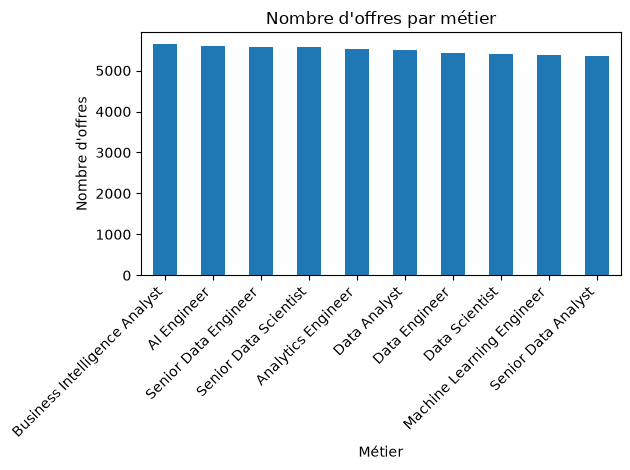

In [20]:
offres["job_title"].value_counts().plot(kind="bar")
plt.title("Nombre d'offres par métier")
plt.xlabel("Métier")
plt.ylabel("Nombre d'offres")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Salaires selon l'expérience

Question : le salaire médian au sein de la fourchette varie-t-il selon le niveau d'expérience ?

Le dataset donne un salaire minimum et un maximum. Je calcule le milieu de cette fourchette pour faciliter la comparaison ; ce n'est pas un salaire réellement observé pour chaque offre.

Cette approche me permet d’obtenir un indicateur synthétique simple pour comparer les groupes d’expérience. En revanche, il faut garder en tête qu’il s’agit d’une approximation construite à partir de la fourchette affichée dans l’offre, et non d’un salaire effectivement versé ou mesuré.

In [21]:
offres["salary_mid_usd"] = (
    offres["salary_min_usd"] + offres["salary_max_usd"]
) / 2

In [22]:
offres.groupby("experience_level").agg(
    nombre_offres=("job_id", "count"),
    salaire_median_usd=("salary_mid_usd", "median")
)

,nombre_offres,salaire_median_usd
experience_level,,
Entry,13877,122824.00
Lead,13702,123335.75
Mid,13649,123338.50
Senior,13772,122627.25


Les salaires médians calculés sont proches entre les niveaux d'expérience, autour de 123 000 USD. La médiane Senior est légèrement inférieure à celles de Mid et Lead.

Ce résultat est intéressant, car on pourrait s’attendre à une progression plus nette avec l’expérience. Ici, dans ce dataset précis, les différences existent mais restent faibles. Cela signifie qu’on ne peut pas conclure, à partir de ce seul tableau, que l’expérience joue un rôle fortement visible sur cet indicateur salarial.

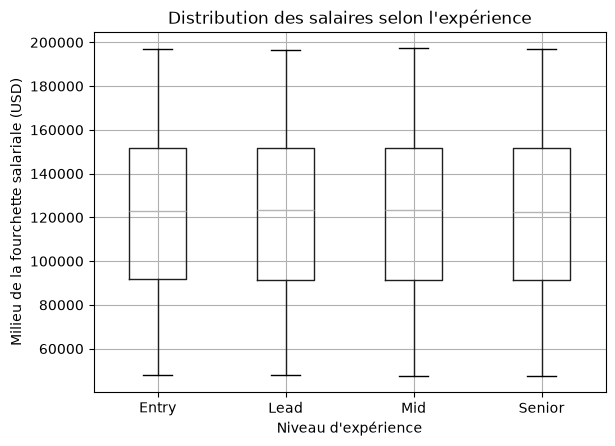

In [23]:
offres.boxplot(column="salary_mid_usd", by="experience_level")
plt.title("Distribution des salaires selon l'expérience")
plt.suptitle("")
plt.xlabel("Niveau d'expérience")
plt.ylabel("Milieu de la fourchette salariale (USD)")
plt.show()

In [24]:
offres["salary_mid_usd"].describe()

count     55000.000000
mean     121991.381282
std       36997.346569
min       47650.500000
25%       91466.625000
50%      123006.750000
75%      151677.625000
max      197221.500000
Name: salary_mid_usd, dtype: float64

In [25]:
offres.groupby("experience_level")["salary_mid_usd"].agg(
    ["count", "min", "median", "max"]
)

,count,min,median,max
experience_level,,,,
Entry,13877,47766.5,122824.00,196806.5
Lead,13702,47772.5,123335.75,196598.5
Mid,13649,47650.5,123338.50,197221.5
Senior,13772,47709.5,122627.25,196803.0


Min et max : 47650.5 197221.5
Échelle du graphique : (np.float64(40171.95), np.float64(204700.05))


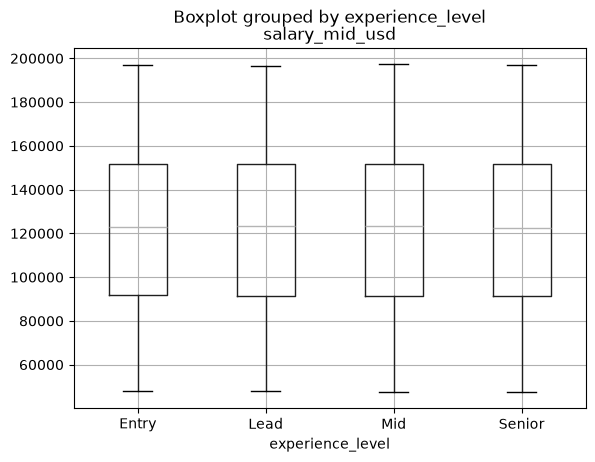

In [26]:
print("Min et max :", offres["salary_mid_usd"].min(), offres["salary_mid_usd"].max())

ax = offres.boxplot(column="salary_mid_usd", by="experience_level")
print("Échelle du graphique :", ax.get_ylim())

plt.show()

Le boxplot montre des distributions de salaires similaires entre les niveaux d'expérience. Les médianes sont proches de 123 000 USD dans ce dataset ; on n'observe pas ici de hausse nette selon le niveau d'expérience.

Le graphique complète bien le tableau précédent, car il ne montre pas seulement une valeur centrale, mais aussi la dispersion des salaires dans chaque groupe. Ici encore, la lecture reste descriptive : les groupes se ressemblent globalement, ce qui va dans le sens d’une différence peu marquée dans ce fichier.

## Modes de travail selon l'expérience

Je cherche ici à savoir si le niveau d’expérience est associé à un mode de travail particulier, c’est-à-dire si certains groupes sont plus souvent en présentiel, en hybride ou en télétravail.

Je commence par comparer les effectifs bruts, puis je regarde les proportions pour neutraliser les petites différences de taille entre les groupes d’expérience.

In [27]:
pd.crosstab(offres["experience_level"], offres["remote_option"])

remote_option,Hybrid,Onsite,Remote
experience_level,,,
Entry,4610,4690,4577
Lead,4568,4627,4507
Mid,4507,4628,4514
Senior,4541,4642,4589


Les effectifs des trois modes de travail sont proches pour chaque niveau d'expérience. Le présentiel est légèrement plus fréquent dans chaque groupe.

Cette première lecture en effectifs bruts suggère qu’il n’existe pas de rupture forte entre les niveaux d’expérience. Je calcule aussi les proportions, car les groupes d'expérience n'ont pas exactement la même taille et une comparaison en pourcentage est plus juste qu’une comparaison uniquement en nombres absolus.

In [28]:
pd.crosstab(
    offres["experience_level"],
    offres["remote_option"],
    normalize="index"
).mul(100).round(1)

remote_option,Hybrid,Onsite,Remote
experience_level,,,
Entry,33.2,33.8,33.0
Lead,33.3,33.8,32.9
Mid,33.0,33.9,33.1
Senior,33.0,33.7,33.3


Les proportions des modes de travail sont très proches d'un niveau d'expérience à l'autre : environ un tiers des offres est Onsite, Hybrid et Remote dans chaque groupe.

Cette stabilité renforce l’idée qu’il n’y a pas, dans ce dataset, de lien très marqué entre expérience et mode de travail. Là encore, cette observation décrit le fichier étudié ; elle ne suffit pas à affirmer que cette répartition est identique sur l’ensemble du marché de l’emploi.

## Comparaisons en pourcentages : expérience et mode de travail

Chaque pourcentage utilise le nombre d'offres de son groupe comme dénominateur.
Les effectifs restent visibles. Les niveaux Entry, Mid, Senior et Lead sont ceux du fichier ;
Entry est utilisé comme approximation de junior, sans déduire l'expérience du titre du poste.

,nombre_offres,pourcentage
experience_level,,
Entry,13877,25.23
Senior,13772,25.04
Lead,13702,24.91
Mid,13649,24.82


Mode de travail selon l'expérience : nombre d'offres (% du niveau)


,Hybrid,Onsite,Remote,effectif_groupe
experience_level,,,,
Entry,"4 610 (33,2 %)","4 690 (33,8 %)","4 577 (33,0 %)",13877
Lead,"4 568 (33,3 %)","4 627 (33,8 %)","4 507 (32,9 %)",13702
Mid,"4 507 (33,0 %)","4 628 (33,9 %)","4 514 (33,1 %)",13649
Senior,"4 541 (33,0 %)","4 642 (33,7 %)","4 589 (33,3 %)",13772


Mode de travail selon le métier : nombre d'offres (% du métier)


,Hybrid,Onsite,Remote,effectif_groupe
job_title,,,,
AI Engineer,"1 822 (32,6 %)","1 839 (32,9 %)","1 934 (34,6 %)",5595
Analytics Engineer,"1 877 (33,9 %)","1 840 (33,2 %)","1 817 (32,8 %)",5534
Business Intelligence Analyst,"1 844 (32,6 %)","1 907 (33,7 %)","1 900 (33,6 %)",5651
Data Analyst,"1 821 (33,1 %)","1 939 (35,2 %)","1 746 (31,7 %)",5506
Data Engineer,"1 822 (33,6 %)","1 866 (34,4 %)","1 732 (32,0 %)",5420
Data Scientist,"1 835 (33,9 %)","1 774 (32,8 %)","1 799 (33,3 %)",5408
Machine Learning Engineer,"1 712 (31,8 %)","1 816 (33,7 %)","1 854 (34,4 %)",5382
Senior Data Analyst,"1 815 (33,9 %)","1 816 (34,0 %)","1 717 (32,1 %)",5348
Senior Data Engineer,"1 847 (33,1 %)","1 901 (34,0 %)","1 836 (32,9 %)",5584


Mode de travail selon le métier et l'expérience : nombre d'offres (% du groupe)


Hybrid        Onsite  \
job_title                     experience_level                               
AI Engineer                   Entry             452 (32,0 %)  440 (31,1 %)   
                              Lead              467 (32,8 %)  479 (33,6 %)   
                              Mid               435 (32,2 %)  456 (33,7 %)   
                              Senior            468 (33,3 %)  464 (33,0 %)   
Analytics Engineer            Entry             495 (34,9 %)  472 (33,2 %)   
                              Lead              442 (32,3 %)  461 (33,6 %)   
                              Mid               470 (34,0 %)  466 (33,7 %)   
                              Senior            470 (34,5 %)  441 (32,4 %)   
Business Intelligence Analyst Entry             450 (32,7 %)  477 (34,6 %)   
                              Lead              475 (33,6 %)  462 (32,7 %)   
                              Mid               435 (32,3 %)  440 (32,7 %)   
                              Senior            484 (32,0 %)  528 (34,9 %)   
Data Analyst                  Entry             470 (33,5 %)  493 (35,2 %)   
                              Lead              484 (35,5 %)  461 (33,8 %)   
                              Mid               437 (31,5 %)  504 (36,3 %)   
                              Senior            430 (31,8 %)  481 (35,6 %)   
Data Engineer                 Entry             499 (35,0 %)  467 (32,8 %)   
                              Lead              445 (32,7 %)  480 (35,3 %)   
                              Mid               457 (35,2 %)  441 (34,0 %)   
                              Senior            421 (31,5 %)  478 (35,8 %)   
Data Scientist                Entry             463 (33,7 %)  462 (33,6 %)   
                              Lead              454 (34,9 %)  439 (33,8 %)   
                              Mid               458 (33,5 %)  434 (31,8 %)   
                              Senior            460 (33,7 %)  439 (32,1 %)   
Machine Learning Engineer     Entry             431 (32,9 %)  426 (32,5 %)   
                              Lead              401 (30,5 %)  460 (35,0 %)   
                              Mid               442 (32,0 %)  472 (34,2 %)   
                              Senior            438 (31,8 %)  458 (33,3 %)   
Senior Data Analyst           Entry             476 (34,5 %)  480 (34,8 %)   
                              Lead              447 (34,4 %)  429 (33,0 %)   
                              Mid               447 (33,3 %)  467 (34,8 %)   
                              Senior            445 (33,6 %)  440 (33,2 %)   
Senior Data Engineer          Entry             455 (31,9 %)  482 (33,8 %)   
                              Lead              462 (32,8 %)  485 (34,4 %)   
                              Mid               462 (33,1 %)  501 (35,9 %)   
                              Senior            468 (34,6 %)  433 (32,0 %)   
Senior Data Scientist         Entry             419 (31,1 %)  491 (36,5 %)   
                              Lead              491 (34,0 %)  471 (32,6 %)   
                              Mid               464 (33,2 %)  447 (32,0 %)   
                              Senior            457 (33,0 %)  480 (34,6 %)   

                                                      Remote  effectif_groupe  
job_title                     experience_level                                 
AI Engineer                   Entry             521 (36,9 %)             1413  
                              Lead              479 (33,6 %)             1425  
                              Mid               462 (34,1 %)             1353  
                              Senior            472 (33,6 %)             1404  
Analytics Engineer            Entry             453 (31,9 %)             1420  
                              Lead              467 (34,1 %)             1370  
                              Mid               446 (32,3 %)             1382  
                              Senior            451 (33,1

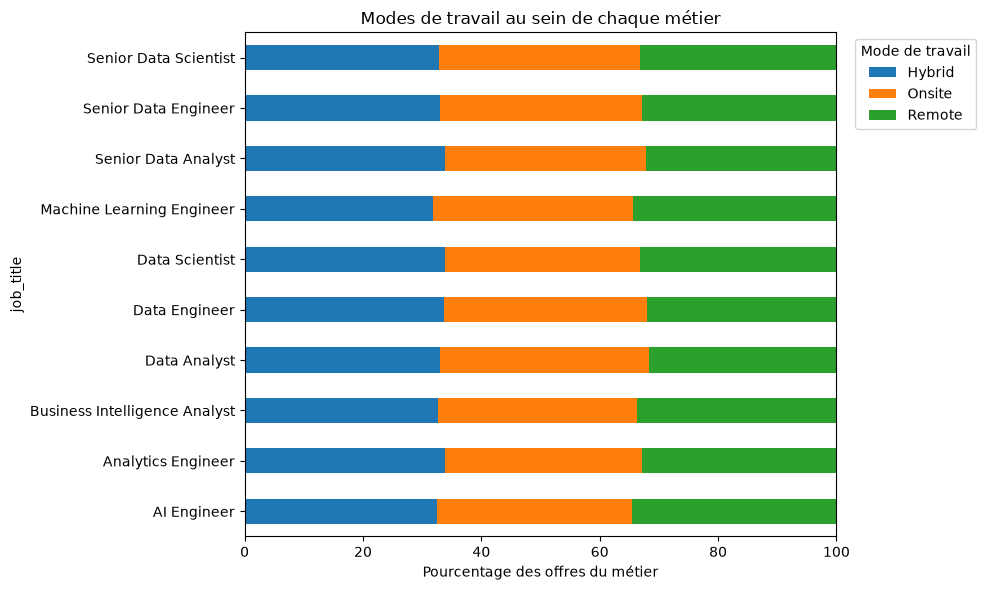

,min,max,ecart_points
remote_option,,,
Hybrid,30.52,35.48,4.97
Onsite,31.14,36.48,5.34
Remote,30.72,36.87,6.15


Chi² experience_level × remote_option : p-value = 0.990
Chi² job_title × remote_option : p-value = 0.045
Une p-value supérieure à 0,05 signifie que les écarts sont compatibles avec le hasard.


In [29]:
from scipy.stats import chi2_contingency

repartition_experience = offres.experience_level.value_counts().rename_axis("experience_level").to_frame("nombre_offres")
repartition_experience["pourcentage"] = repartition_experience.nombre_offres / len(offres) * 100
display(repartition_experience.round(2))

modes_metier = group_percentages(offres, ["job_title"], "remote_option")
modes_croises = group_percentages(offres, ["job_title", "experience_level"], "remote_option")

def tableau_effectifs_pourcentages(resultat, groupes):
    """Une case = nombre d'offres (pourcentage du groupe) ; effectif du groupe en dernière colonne."""
    resultat = resultat.assign(case=resultat.apply(
        lambda r: f"{r.nombre_offres:,} ({r.pourcentage:.1f} %)".replace(",", " ").replace(".", ","), axis=1))
    tableau = resultat.pivot_table(index=groupes, columns="remote_option", values="case", aggfunc="first")
    tableau["effectif_groupe"] = resultat.groupby(groupes).effectif_groupe.first()
    tableau.columns.name = None
    return tableau

# Mode de travail selon l'expérience
modes_experience = group_percentages(offres, ["experience_level"], "remote_option")
print("Mode de travail selon l'expérience : nombre d'offres (% du niveau)")
display(tableau_effectifs_pourcentages(modes_experience, ["experience_level"]))

# Mode de travail selon le métier
print("Mode de travail selon le métier : nombre d'offres (% du métier)")
display(tableau_effectifs_pourcentages(modes_metier, ["job_title"]))

# Mode de travail selon le métier et l'expérience
print("Mode de travail selon le métier et l'expérience : nombre d'offres (% du groupe)")
with pd.option_context("display.max_rows", 60):
    display(tableau_effectifs_pourcentages(modes_croises, ["job_title", "experience_level"]))

graphique_modes = modes_metier.pivot(index="job_title", columns="remote_option", values="pourcentage").fillna(0)
graphique_modes.plot.barh(stacked=True, figsize=(10, 6))
plt.title("Modes de travail au sein de chaque métier")
plt.xlabel("Pourcentage des offres du métier")
plt.xlim(0, 100)
plt.legend(title="Mode de travail", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

ecarts_modes = modes_croises.groupby("remote_option").pourcentage.agg(["min", "max"])
ecarts_modes["ecart_points"] = ecarts_modes["max"] - ecarts_modes["min"]
display(ecarts_modes.round(2))

# Test du chi² : les écarts observés sont-ils plus grands que ce que le hasard produirait ?
for variable in ["experience_level", "job_title"]:
    p_value = chi2_contingency(pd.crosstab(offres[variable], offres["remote_option"]))[1]
    print(f"Chi² {variable} × remote_option : p-value = {p_value:.3f}")
print("Une p-value supérieure à 0,05 signifie que les écarts sont compatibles avec le hasard.")

**Lecture.** Dans chaque métier et chaque croisement métier × expérience, les trois modes de travail restent entre 30,5 % et 36,9 %. Chaque groupe croisé contient environ 1 300 à 1 500 offres, les pourcentages reposent donc sur des effectifs suffisants.

Le test du chi² le confirme :
- **expérience × mode de travail** : p ≈ 0,99. Aucun lien : un junior et un senior ont la même probabilité d'être en télétravail dans ce fichier ;
- **métier × mode de travail** : p ≈ 0,045, juste sous le seuil de 5 %. L'écart le plus visible est que Data Analyst est un peu plus souvent en présentiel (35,2 %) et moins en télétravail (31,7 %). Comme nous faisons deux tests, ce résultat limite reste fragile : l'écart est de quelques points seulement.

Conclusion : dans ce dataset, le mode de travail ne dépend ni de l'expérience, ni (de façon nette) du métier.

## Compétences les plus demandées

Question : quelles compétences sont les plus souvent associées aux offres ?

Je relie la table des offres à la table de liaison avec `job_id`, puis je compte les offres associées à chaque compétence.

Cette partie est importante pour le projet JobMatch, car elle permet de relier les métiers aux compétences demandées. L’objectif n’est pas seulement de produire un classement, mais aussi de voir si certaines compétences se détachent clairement ou si les écarts restent faibles entre les plus fréquentes.

In [30]:
offres_competences = offres.merge(
    competences_offres,
    on="job_id",
    how="left",
    validate="one_to_many"
)

# On compte des offres distinctes (une compétence citée deux fois dans une offre ne compte qu'une fois)
offres_competences.groupby("skill").job_id.nunique().sort_values(ascending=False).head(15)

skill
Kafka                 9665
Tableau               9660
Data Visualization    9655
NLP                   9616
SQL                   9602
ETL                   9597
BigQuery              9562
NumPy                 9558
Pandas                9544
GCP                   9541
dbt                   9537
Airflow               9526
Deep Learning         9505
PyTorch               9504
TensorFlow            9497
Name: job_id, dtype: int64

Les 15 compétences les plus fréquentes apparaissent chacune dans environ 9 500 à 9 700 offres. Kafka est la plus fréquente parmi elles, mais l'écart avec les autres reste faible.

Cela signifie que le haut du classement est relativement resserré : il existe bien une compétence en tête, mais aucune ne domine massivement les autres. Cette répartition décrit les données fournies et ne prouve pas, à elle seule, que ces compétences sont les plus demandées sur tout le marché.

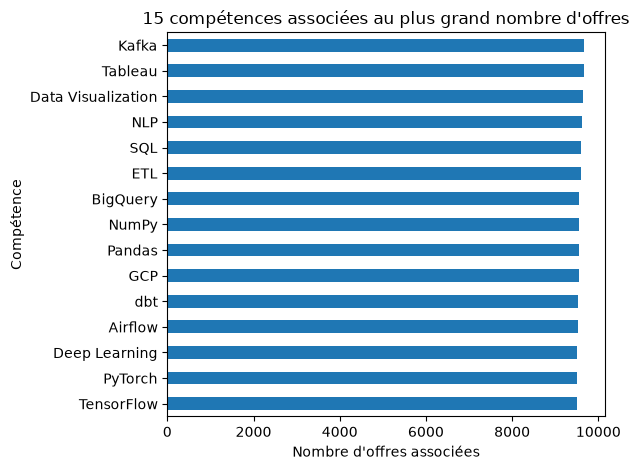

In [31]:
top_competences = (
    offres_competences.groupby("skill").job_id.nunique()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

top_competences.plot(kind="barh")
plt.title("15 compétences associées au plus grand nombre d'offres")
plt.xlabel("Nombre d'offres associées")
plt.ylabel("Compétence")
plt.tight_layout()
plt.show()

Le graphique confirme que les effectifs des quinze compétences sont proches. Kafka arrive en tête, mais aucune compétence ne se distingue nettement des autres dans cette sélection.

La visualisation aide surtout à lire plus rapidement le classement et à voir que les écarts sont faibles. Elle confirme donc l’idée principale du tableau : on observe une hiérarchie légère, mais pas de domination écrasante d’une seule compétence.

## Compétences demandées ensemble

Chaque paire est comptée au maximum une fois par offre. Le support est la part de toutes
les offres contenant les deux compétences. Le lift compare cette fréquence à celle attendue
si les deux compétences étaient indépendantes : proche de 1, il ne signale pas d'association forte.
Un classement de paires fréquentes ne suffit donc pas à conclure qu'elles sont particulièrement liées.

,competence_1,competence_2,nombre_offres,support_pct,lift
rang,,,,,
1,BigQuery,SQL,1527,2.776,0.915
2,Airflow,Tableau,1526,2.775,0.912
3,Data Visualization,ETL,1520,2.764,0.902
4,NumPy,PyTorch,1520,2.764,0.920
5,GCP,NLP,1518,2.760,0.910
6,BigQuery,Data Visualization,1512,2.749,0.901
7,Data Visualization,TensorFlow,1512,2.749,0.907
8,NumPy,Tableau,1509,2.744,0.899
9,Data Visualization,Tableau,1508,2.742,0.889


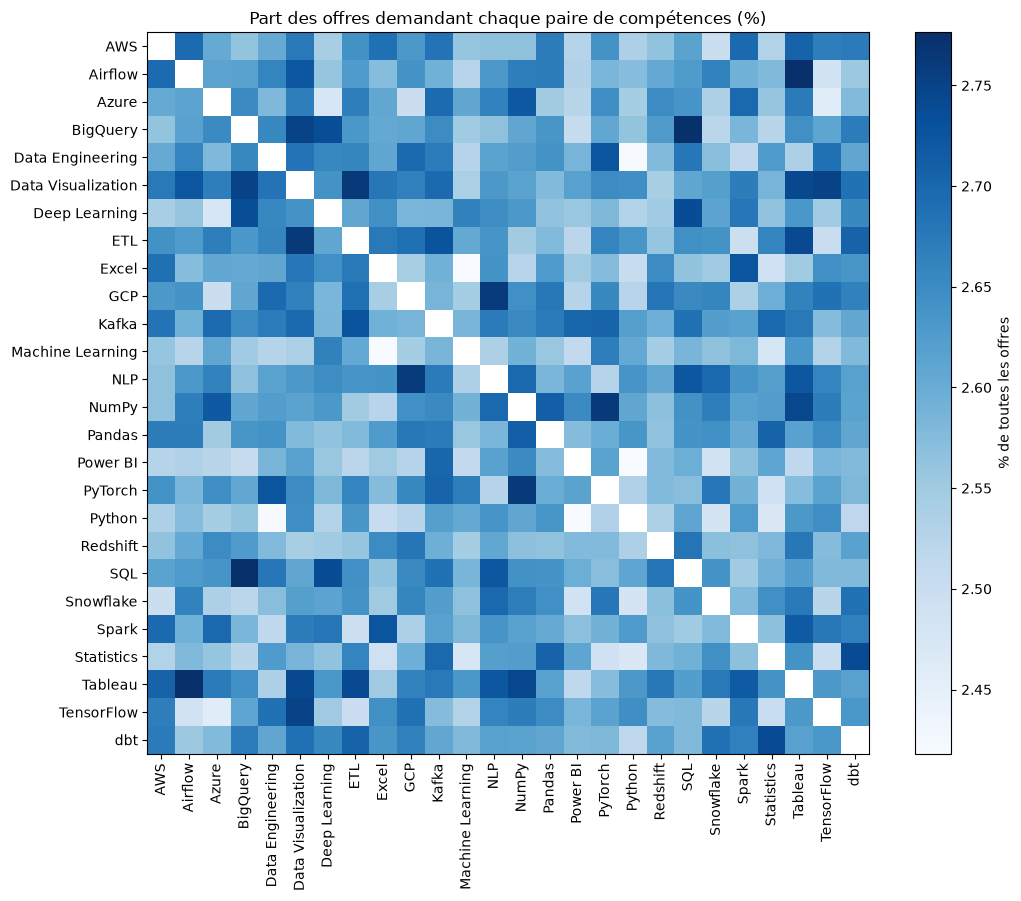

In [32]:
paires = skill_pairs(offres, competences_offres)
top_paires = paires.head(20).reset_index(drop=True)
top_paires.index = pd.RangeIndex(1, len(top_paires) + 1, name="rang")  # 1 = paire la plus fréquente
display(top_paires.round(3))
matrice_paires = paires.pivot(index="competence_1", columns="competence_2", values="support_pct")
noms_competences = sorted(liste_competences.skill.unique())
matrice_paires = matrice_paires.reindex(index=noms_competences, columns=noms_competences)
matrice_paires = matrice_paires.combine_first(matrice_paires.T)
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(matrice_paires.to_numpy(), cmap="Blues")
ax.set_xticks(range(len(noms_competences)), noms_competences, rotation=90)
ax.set_yticks(range(len(noms_competences)), noms_competences)
ax.set_title("Part des offres demandant chaque paire de compétences (%)")
fig.colorbar(image, ax=ax, label="% de toutes les offres")
plt.tight_layout()
plt.show()

**Lecture.** Les paires les plus fréquentes (BigQuery + SQL, Airflow + Tableau, NumPy + PyTorch…) apparaissent chacune dans environ 2,8 % des offres, mais **toutes ont un lift inférieur à 1 (≈ 0,91)**. Aucune paire n'est donc demandée ensemble plus souvent que le hasard ne le prévoit.

Ce lift légèrement inférieur à 1 s'explique par la construction des données : chaque offre contient entre 3 et 6 compétences (4,5 en moyenne) parmi 26. Quand une offre contient déjà une compétence, il reste moins de « places » pour les autres, ce qui crée mécaniquement une petite association négative.

Conclusion : contrairement à ce qu'on observerait sur un vrai marché (où SQL et Python, ou Python et Pandas, vont souvent ensemble), ce dataset **ne contient pas de groupes de compétences liés**. C'est un indice que les compétences ont été attribuées au hasard aux offres.

## Familles de compétences

Plusieurs des 26 compétences du fichier sont **proches ou concurrentes**. Par exemple, Tableau et Power BI sont deux logiciels qui font la même chose (des tableaux de bord), et une entreprise utilise en général l'un **ou** l'autre. Les compter séparément dans un classement disperse l'information. Je les regroupe donc en **9 familles**, selon l'usage de chaque outil :

| Famille | Compétences | À quoi elles servent |
|---|---|---|
| SQL | SQL | interroger une base de données |
| Entrepôts cloud | BigQuery, Redshift, Snowflake | stocker et interroger de gros volumes dans le cloud |
| Cloud | AWS, GCP, Azure | plateformes cloud concurrentes |
| Visualisation / BI | Tableau, Power BI, Data Visualization, Excel | présenter les données (graphiques, tableaux de bord) |
| Pipelines / Data Engineering | Airflow, dbt, ETL, Data Engineering | transporter, transformer et automatiser les flux de données |
| Big Data / streaming | Spark, Kafka | traiter des données massives ou en temps réel |
| Python et librairies | Python, Pandas, NumPy | programmer et manipuler des données |
| Machine Learning / IA | Machine Learning, Deep Learning, TensorFlow, PyTorch, NLP | construire des modèles prédictifs |
| Statistiques | Statistics | méthodes statistiques |

Ce regroupement est un **choix de notre part** : il repose sur l'usage des outils, pas sur une information du fichier. Une offre qui demande à la fois Tableau et Power BI ne compte qu'**une fois** dans la famille Visualisation / BI.

Remarque : Airflow (automatisation de pipelines) et Tableau (visualisation) appartiennent à deux familles différentes. Le fait que cette paire arrive 2e du classement précédent n'a donc pas de logique métier.

,nombre_offres,pct_offres,nombre_competences,competences
famille,,,,
Machine Learning / IA,34916,63.5,5,"Machine Learning, Deep Learning, TensorFlow, P..."
Visualisation / BI,30252,55.0,4,"Tableau, Power BI, Data Visualization, Excel"
Pipelines / Data Engineering,30201,54.9,4,"Airflow, dbt, ETL, Data Engineering"
Cloud,24460,44.5,3,"AWS, GCP, Azure"
Entrepôts cloud,24382,44.3,3,"BigQuery, Redshift, Snowflake"
Python et librairies,24252,44.1,3,"Python, Pandas, NumPy"
Big Data / streaming,17698,32.2,2,"Spark, Kafka"
SQL,9602,17.5,1,SQL
Statistiques,9446,17.2,1,Statistics


,competence_1,competence_2,nombre_offres,support_pct,lift
rang,,,,,
1,Machine Learning / IA,Visualisation / BI,17920,32.582,0.933
2,Machine Learning / IA,Pipelines / Data Engineering,17893,32.533,0.933
3,Pipelines / Data Engineering,Visualisation / BI,15523,28.224,0.934
4,Cloud,Machine Learning / IA,14421,26.220,0.929
5,Machine Learning / IA,Python et librairies,14363,26.115,0.933
6,Entrepôts cloud,Machine Learning / IA,14354,26.098,0.927
7,Cloud,Pipelines / Data Engineering,12447,22.631,0.927
8,Entrepôts cloud,Pipelines / Data Engineering,12404,22.553,0.926
9,Cloud,Visualisation / BI,12369,22.489,0.919


Lift des paires de familles : de 0.864 à 0.934


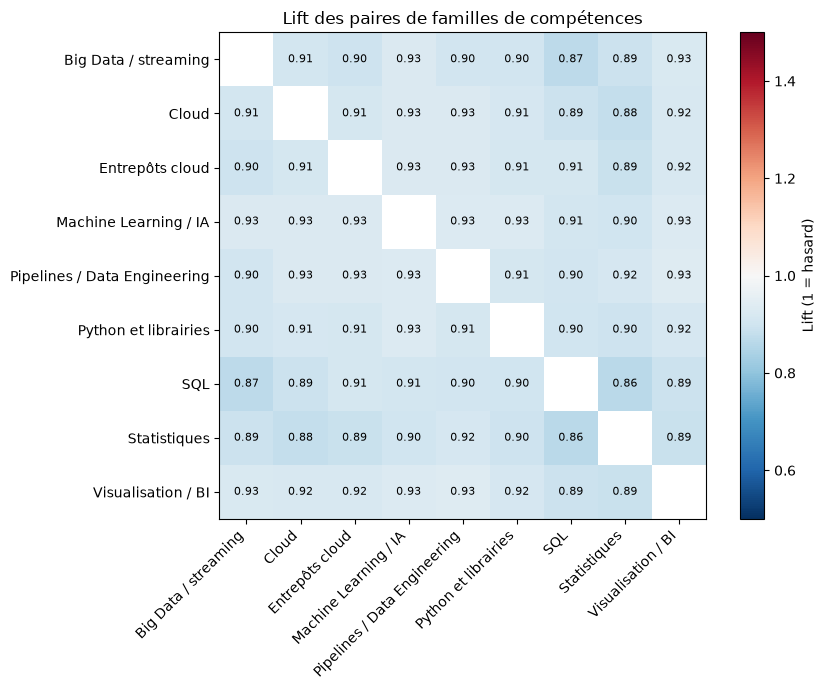

In [33]:
import numpy as np
from src.analysis import SKILL_FAMILIES, to_skill_families

familles_offres = to_skill_families(competences_offres)
composition = pd.Series(SKILL_FAMILIES).rename_axis("competence").reset_index(name="famille").groupby("famille").competence.agg(", ".join)

frequence_familles = familles_offres.groupby("skill").job_id.nunique().rename("nombre_offres").to_frame()
frequence_familles["pct_offres"] = frequence_familles.nombre_offres / offres.job_id.nunique() * 100
frequence_familles["nombre_competences"] = pd.Series(SKILL_FAMILIES).value_counts()
frequence_familles["competences"] = composition
frequence_familles.index.name = "famille"
display(frequence_familles.sort_values("nombre_offres", ascending=False).round(1))

# Paires de familles : support et lift, comme pour les compétences
paires_familles = skill_pairs(offres, familles_offres).reset_index(drop=True)
paires_familles.index = pd.RangeIndex(1, len(paires_familles) + 1, name="rang")
display(paires_familles.head(10).round(3))
print(f"Lift des paires de familles : de {paires_familles.lift.min():.3f} à {paires_familles.lift.max():.3f}")

# Heatmap du lift : blanc = 1 (hasard), rouge = plus souvent ensemble, bleu = moins souvent
from matplotlib.colors import TwoSlopeNorm
noms_familles = sorted(frequence_familles.index)
matrice_lift = paires_familles.pivot(index="competence_1", columns="competence_2", values="lift")
matrice_lift = matrice_lift.reindex(index=noms_familles, columns=noms_familles)
matrice_lift = matrice_lift.combine_first(matrice_lift.T)
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(matrice_lift.to_numpy(), cmap="RdBu_r", norm=TwoSlopeNorm(vmin=0.5, vcenter=1, vmax=1.5))
ax.set_xticks(range(len(noms_familles)), noms_familles, rotation=45, ha="right")
ax.set_yticks(range(len(noms_familles)), noms_familles)
for (ligne, colonne), valeur in np.ndenumerate(matrice_lift.to_numpy()):
    if not np.isnan(valeur):
        ax.text(colonne, ligne, f"{valeur:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Lift (1 = hasard)")
ax.set_title("Lift des paires de familles de compétences")
plt.tight_layout()
plt.show()

**Lecture.**
- **Fréquence des familles** : Machine Learning / IA est la famille la plus demandée (63,5 % des offres), devant Visualisation / BI (55,0 %) et Pipelines / Data Engineering (54,9 %). SQL n'apparaît que dans **17,5 %** des offres. Attention : une famille qui regroupe beaucoup d'outils a mécaniquement plus de chances d'être citée. Machine Learning / IA en contient 5, alors que SQL et Statistiques n'en contiennent qu'un, d'où la colonne `nombre_competences`.
- **Paires de familles** : les paires les plus fréquentes, comme Machine Learning / IA + Visualisation / BI (32,6 % des offres), sont simplement celles des deux familles les plus fréquentes. **Tous les lifts sont entre 0,86 et 0,93**, donc tous inférieurs à 1.
- **Heatmap** : toutes les cases sont bleu clair, ce qui veut dire un lift un peu inférieur à 1. Aucune case n'est rouge : aucune famille n'est demandée avec une autre plus souvent que le hasard. Contrairement à la heatmap précédente, l'échelle est **centrée sur 1** : les couleurs montrent l'écart au hasard, et non de petites différences de fréquence.

Conclusion : le regroupement rend le classement plus lisible (9 familles au lieu de 26 outils), mais ne fait apparaître **aucune association**. Sur un vrai marché, on s'attendrait par exemple à ce que Python et Machine Learning / IA, ou Entrepôts cloud et SQL, soient souvent demandés ensemble (lift supérieur à 1). De plus, SQL dans seulement 17,5 % des offres de data est peu réaliste : c'est l'une des compétences les plus demandées dans ces métiers.

## Compétences selon le métier

Le classement général des compétences mélange tous les métiers. Or un Data Analyst et un AI Engineer ne devraient pas avoir besoin des mêmes compétences. Pour chaque métier, je calcule donc la **part de ses offres qui demandent chaque famille**. Le dénominateur est le nombre d'offres du métier, et une offre peut demander plusieurs familles, donc une ligne peut dépasser 100 %.

Je teste ensuite, famille par famille, si la part des offres qui la demandent change selon le métier (test du chi², avec correction de Bonferroni pour 9 tests).

skill,Big Data / streaming,Cloud,Entrepôts cloud,Machine Learning / IA,Pipelines / Data Engineering,Python et librairies,SQL,Statistiques,Visualisation / BI
job_title,,,,,,,,,
AI Engineer,32.2,46.0,42.9,63.7,55.2,43.6,18.1,17.4,55.9
Analytics Engineer,32.3,44.2,44.6,63.2,53.8,44.7,17.5,17.0,54.2
Business Intelligence Analyst,32.2,43.6,44.2,63.7,55.4,43.8,16.9,16.7,55.2
Data Analyst,33.0,44.0,44.6,63.0,55.9,43.2,17.8,17.3,54.4
Data Engineer,32.4,45.1,44.6,63.2,53.6,44.2,17.8,17.1,55.6
Data Scientist,31.0,44.6,44.4,64.4,54.1,43.5,18.5,17.6,55.4
Machine Learning Engineer,32.3,45.2,44.0,63.7,55.2,44.6,16.5,16.7,54.9
Senior Data Analyst,32.2,43.0,45.3,62.5,55.6,44.9,17.5,17.4,54.1
Senior Data Engineer,31.6,45.0,44.6,64.0,55.1,43.5,17.1,17.3,54.9


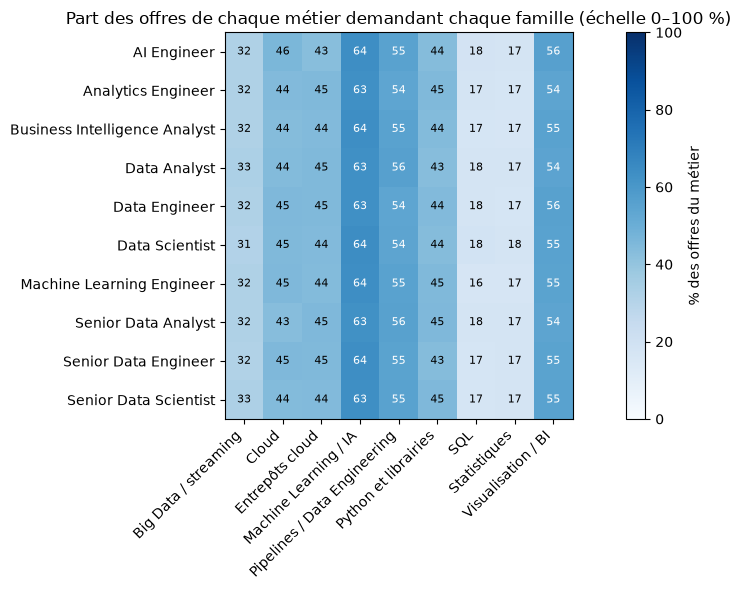

,min_pct,max_pct,ecart_points,V_cramer,p_value,significatif_apres_correction
famille,,,,,,
Cloud,43.025,46.041,3.016,0.017,0.074,False
SQL,16.462,18.473,2.010,0.015,0.180,False
Pipelines / Data Engineering,53.579,55.866,2.287,0.015,0.189,False
Python et librairies,43.153,45.011,1.858,0.013,0.414,False
Visualisation / BI,54.095,55.943,1.848,0.012,0.594,False
Entrepôts cloud,42.949,45.307,2.358,0.012,0.596,False
Big Data / streaming,31.010,32.964,1.954,0.011,0.666,False
Machine Learning / IA,62.509,64.423,1.914,0.010,0.741,False
Statistiques,16.722,17.567,0.844,0.007,0.974,False


Data Analyst vs AI Engineer (% des offres) :


job_title,Data Analyst,AI Engineer
skill,,
Big Data / streaming,33.0,32.2
Cloud,44.0,46.0
Entrepôts cloud,44.6,42.9
Machine Learning / IA,63.0,63.7
Pipelines / Data Engineering,55.9,55.2
Python et librairies,43.2,43.6
SQL,17.8,18.1
Statistiques,17.3,17.4
Visualisation / BI,54.4,55.9


In [34]:
familles_metier = skill_prevalence(offres, familles_offres, "job_title")
display(familles_metier.round(1))

fig, ax = plt.subplots(figsize=(11, 6))
image = ax.imshow(familles_metier.to_numpy(), cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(familles_metier.shape[1]), familles_metier.columns, rotation=45, ha="right")
ax.set_yticks(range(familles_metier.shape[0]), familles_metier.index)
for (ligne, colonne), valeur in np.ndenumerate(familles_metier.to_numpy()):
    ax.text(colonne, ligne, f"{valeur:.0f}", ha="center", va="center", fontsize=8,
            color="white" if valeur > 50 else "black")
fig.colorbar(image, ax=ax, label="% des offres du métier")
ax.set_title("Part des offres de chaque métier demandant chaque famille (échelle 0–100 %)")
plt.tight_layout()
plt.show()

lignes = []
for famille in familles_metier.columns:
    demande = offres.job_id.isin(familles_offres.loc[familles_offres.skill.eq(famille), "job_id"])
    tableau = pd.crosstab(offres.job_title, demande)
    chi2, p_value = chi2_contingency(tableau)[:2]
    lignes.append({"famille": famille,
                   "min_pct": familles_metier[famille].min(), "max_pct": familles_metier[famille].max(),
                   "ecart_points": familles_metier[famille].max() - familles_metier[famille].min(),
                   "V_cramer": np.sqrt(chi2 / tableau.to_numpy().sum()),
                   "p_value": p_value})
tests_familles = pd.DataFrame(lignes).set_index("famille").sort_values("p_value")
tests_familles["significatif_apres_correction"] = tests_familles.p_value < 0.05 / len(tests_familles)
display(tests_familles.round(3))

print("Data Analyst vs AI Engineer (% des offres) :")
display(familles_metier.loc[["Data Analyst", "AI Engineer"]].T.round(1))

**Lecture.**
- Pour chaque famille, la part des offres qui la demandent est **presque identique d'un métier à l'autre**. L'écart maximal entre deux métiers est de 3 points (Cloud : de 43,0 % à 46,0 %).
- Le test du chi² ne trouve **aucune différence significative** entre métiers, pour aucune des 9 familles (toutes les p-values sont supérieures à 0,05, avant même la correction). Le V de Cramér est inférieur à 0,02 : le lien entre métier et compétences demandées est nul.
- Comparaison concrète : **63,0 %** des offres Data Analyst demandent du Machine Learning / IA, contre **63,7 %** pour AI Engineer. À l'inverse, **55,9 %** des offres AI Engineer demandent de la Visualisation / BI, contre **54,4 %** pour Data Analyst.

Conclusion : dans ce fichier, **les compétences demandées ne dépendent pas du métier**. Ce n'est pas réaliste : un poste d'AI Engineer devrait demander bien plus souvent TensorFlow ou PyTorch qu'un poste de Data Analyst, qui devrait demander davantage SQL, Excel ou Power BI. Le top 15 des compétences calculé sur toutes les offres contient donc des compétences **qui ne sont pas nécessaires** pour un métier donné.

Cette limite est importante pour JobMatch : avec ce dataset, on **ne peut pas recommander des compétences propres à un métier**, puisque tous les métiers ont le même profil de compétences. Il faudrait pour cela un jeu de données réel, par exemple des offres collectées sur des sites d'emploi.

## Compétences selon l'expérience : Entry et Senior

Le dénominateur est le nombre total d'offres de chaque niveau, et non le nombre de liens
offre-compétence. Une offre peut demander plusieurs compétences : la somme des pourcentages
peut dépasser 100 %. On compare aussi Entry et Senior au sein de Data Analyst pour limiter
les différences de composition entre métiers. Les écarts restent descriptifs.

experience_level
Entry     13877
Lead      13702
Mid       13649
Senior    13772
Name: effectif_groupe, dtype: int64

experience_level,Entry,Senior,ecart_Senior_Entry_points
skill,,,
Pandas,16.77,17.61,0.84
Power BI,16.64,17.30,0.66
Excel,16.78,17.35,0.57
Deep Learning,16.84,17.38,0.54
Python,16.95,17.35,0.41
SQL,17.42,17.78,0.36
PyTorch,17.13,17.46,0.33
GCP,17.33,17.64,0.31
Data Engineering,17.20,17.49,0.29


experience_level
Entry     1401
Lead      1364
Mid       1389
Senior    1352
Name: effectif_Data_Analyst, dtype: int64

experience_level,Entry,Senior,ecart_Senior_Entry_points
skill,,,
Redshift,16.77,19.30,2.53
ETL,16.42,18.93,2.52
TensorFlow,16.13,18.49,2.36
Pandas,15.99,17.90,1.91
Deep Learning,17.06,18.86,1.80
NumPy,16.49,17.90,1.41
Kafka,17.56,18.79,1.23
Tableau,16.49,17.68,1.19
Machine Learning,16.56,17.68,1.12


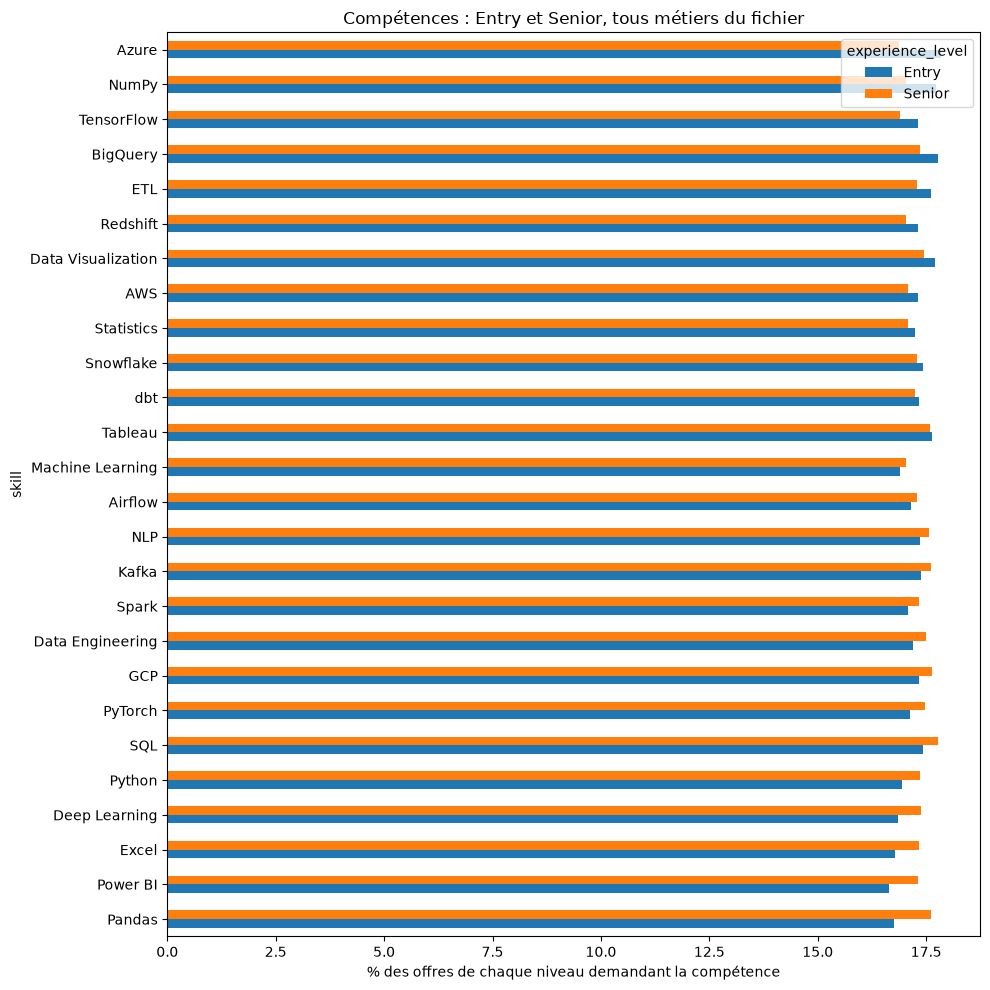

In [35]:
def comparer_entry_senior(selection):
    frequences = skill_prevalence(selection, competences_offres, "experience_level")
    comparaison = frequences.reindex(["Entry", "Senior"]).T
    comparaison["ecart_Senior_Entry_points"] = comparaison.Senior - comparaison.Entry
    return comparaison.sort_values("ecart_Senior_Entry_points", ascending=False)

display(offres.groupby("experience_level").size().rename("effectif_groupe"))
comparaison_competences = comparer_entry_senior(offres)
display(comparaison_competences.round(2))
offres_da = offres.loc[offres.job_title.eq("Data Analyst")]
display(offres_da.groupby("experience_level").size().rename("effectif_Data_Analyst"))
display(comparer_entry_senior(offres_da).round(2))
comparaison_competences[["Entry", "Senior"]].plot.barh(figsize=(10, 10))
plt.xlabel("% des offres de chaque niveau demandant la compétence")
plt.title("Compétences : Entry et Senior, tous métiers du fichier")
plt.tight_layout()
plt.show()

In [36]:
def tester_entry_senior(selection):
    """Chi² par compétence : part des offres Entry vs Senior qui la demandent."""
    niveaux = selection.loc[selection.experience_level.isin(["Entry", "Senior"])]
    liens = competences_offres[["job_id", "skill"]].drop_duplicates()
    lignes = []
    for competence in sorted(liens.skill.unique()):
        demande = niveaux.job_id.isin(liens.loc[liens.skill.eq(competence), "job_id"])
        table = pd.crosstab(niveaux.experience_level, demande)
        part = table[True] / table.sum(axis=1) * 100
        lignes.append({"competence": competence,
                       "ecart_Senior_Entry_points": part["Senior"] - part["Entry"],
                       "p_value": chi2_contingency(table)[1]})
    resultat = pd.DataFrame(lignes).set_index("competence").sort_values("p_value")
    # Correction de Bonferroni : on teste 26 compétences, donc le seuil devient 0,05 / 26
    resultat["significatif_apres_correction"] = resultat.p_value < 0.05 / len(resultat)
    return resultat

tests_da = tester_entry_senior(offres_da)
display(tests_da.head(8).round(4))
print("Compétences significatives (Data Analyst) :", tests_da.significatif_apres_correction.sum(), "/", len(tests_da))
print("Compétences significatives (tous métiers) :", tester_entry_senior(offres).significatif_apres_correction.sum(), "/", len(tests_da))

,ecart_Senior_Entry_points,p_value,significatif_apres_correction
competence,,,
Airflow,-3.8315,0.0085,False
ETL,2.5181,0.0925,False
BigQuery,-2.5027,0.0932,False
Redshift,2.5310,0.0934,False
TensorFlow,2.3598,0.1126,False
SQL,-2.0537,0.1746,False
Pandas,1.9108,0.1985,False
Deep Learning,1.8017,0.2372,False


Compétences significatives (Data Analyst) : 0 / 26


Compétences significatives (tous métiers) : 0 / 26


**Lecture.** Au sein de Data Analyst, l'écart le plus grand concerne Airflow (−3,8 points chez les Senior), puis ETL, BigQuery et Redshift (environ ±2,5 points). Mais comme on compare 26 compétences à la fois, on applique la correction de Bonferroni (seuil 0,05 / 26 ≈ 0,002). Avec cette correction, **aucune compétence n'a un écart significatif** entre Entry et Senior, ni pour Data Analyst, ni tous métiers confondus.

Conclusion : dans ce fichier, **les compétences demandées n'évoluent pas avec le niveau d'expérience**. Les petits écarts observés sont compatibles avec le hasard. Cela ne prouve pas que c'est le cas sur le marché réel, où l'on s'attendrait plutôt à ce que les postes seniors demandent davantage d'outils d'ingénierie (Airflow, Spark, dbt).

## Répartition des offres par pays

Question : quels pays ont le plus d'offres dans le dataset ?

Un diagramme en barres horizontales permet de comparer les pays et de lire facilement leurs noms. Cette visualisation est adaptée ici, car elle rend les libellés plus lisibles qu’un graphique vertical et permet de mieux comparer des effectifs proches.

L’objectif de cette partie est de voir si certains pays occupent une place très dominante dans le dataset ou si, au contraire, la distribution reste relativement équilibrée.

,nombre_offres,part_dataset_pct
country,,
France,4398,8.00
Canada,4314,7.84
Ireland,4287,7.79
Australia,4261,7.75
United Kingdom,4249,7.73
Germany,4232,7.69
Netherlands,4218,7.67
Singapore,4211,7.66
UAE,4204,7.64


Couverture : 13 pays, 55,000 offres, soit 100 % du fichier.


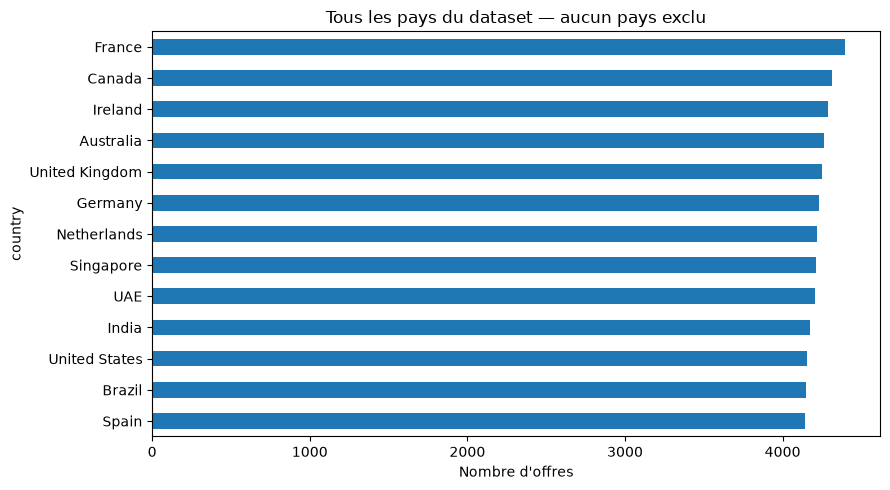

In [37]:
bilan_pays = offres.groupby("country").agg(nombre_offres=("job_id", "nunique"))
bilan_pays["part_dataset_pct"] = bilan_pays.nombre_offres / len(offres) * 100
bilan_pays = bilan_pays.sort_values("nombre_offres", ascending=False)
display(bilan_pays.round(2))
print(f"Couverture : {len(bilan_pays)} pays, {bilan_pays.nombre_offres.sum():,} offres, soit 100 % du fichier.")
bilan_pays.nombre_offres.sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("Tous les pays du dataset — aucun pays exclu")
plt.xlabel("Nombre d'offres")
plt.tight_layout()
plt.show()

Les 13 pays sont conservés : aucune sélection arbitraire des dix premiers n'est nécessaire.
Le tableau donne les effectifs et le poids de chaque pays dans le fichier.
Ces poids décrivent la collecte, pas la part de chaque pays dans le marché mondial.
Nous ne disposons ni du plan d'échantillonnage, ni de taux de couverture nationaux, ni de pondérations.
Les comparaisons de salaire en USD ne corrigent pas le coût de la vie, le temps de travail
ou la fiscalité ; la période de rémunération doit aussi être confirmée dans la documentation source.

## Salaires comparés par métier, expérience et pays

La moyenne seule ne suffit pas : elle peut être tirée par quelques valeurs extrêmes. Pour chaque groupe, je donne donc l'effectif, la moyenne, **le premier quartile (Q1), la médiane, le troisième quartile (Q3)** et l'écart-type. La médiane partage les offres en deux moitiés ; l'intervalle Q1–Q3 contient les 50 % d'offres centrales.

La variable étudiée est le milieu de la fourchette en USD, pas un salaire versé. Je compare d'abord chaque dimension séparément, puis les trois ensemble. Je calcule enfin, pour chaque variable, la part de la variation des salaires qu'elle explique à elle seule (η², rapport de corrélation).

Le seuil de 30 offres pour les groupes croisés est une règle de lisibilité fixée à l'avance. Ici, le plus petit groupe métier × expérience × pays contient 70 offres : les 520 groupes sont conservés.

job_title


,nombre_offres,moyenne_usd,q1_usd,mediane_usd,q3_usd,ecart_type_usd
job_title,,,,,,
Senior Data Analyst,5348,77466.0,66256.0,77274.0,88526.0,13620.0
Data Analyst,5506,77456.0,66051.0,77289.0,88854.0,13725.0
Business Intelligence Analyst,5651,77619.0,66533.0,77470.0,88624.0,13613.0
Data Scientist,5408,124801.0,107482.0,124276.0,141978.0,20616.0
Senior Data Scientist,5572,125347.0,107444.0,125354.0,143536.0,20794.0
Senior Data Engineer,5584,147113.0,125982.0,146663.0,168336.0,24621.0
Machine Learning Engineer,5382,147264.0,126098.0,147402.0,168596.0,24966.0
Analytics Engineer,5534,147416.0,126814.0,147584.0,168131.0,24643.0
Data Engineer,5420,147520.0,126460.0,147772.0,168579.0,24926.0


experience_level


,nombre_offres,moyenne_usd,q1_usd,mediane_usd,q3_usd,ecart_type_usd
experience_level,,,,,,
Senior,13772,121922.0,91325.0,122627.0,151816.0,37059.0
Entry,13877,121921.0,91811.0,122824.0,151496.0,36683.0
Lead,13702,121941.0,91322.0,123336.0,151831.0,37125.0
Mid,13649,122184.0,91453.0,123338.0,151616.0,37129.0


country


,nombre_offres,moyenne_usd,q1_usd,mediane_usd,q3_usd,ecart_type_usd
country,,,,,,
Australia,4261,121546.0,90352.0,121614.0,152148.0,37266.0
Brazil,4151,121669.0,91178.0,122008.0,151490.0,37218.0
Singapore,4211,121578.0,91733.0,122017.0,151731.0,36809.0
Germany,4232,121472.0,90270.0,122140.0,151846.0,37253.0
France,4398,121763.0,90889.0,122281.0,151259.0,37073.0
Ireland,4287,121487.0,90723.0,122398.0,150725.0,36855.0
Spain,4145,121456.0,90859.0,122980.0,151167.0,37079.0
United Kingdom,4249,122297.0,92590.0,123195.0,151243.0,36809.0
Netherlands,4218,122306.0,91572.0,123504.0,152301.0,36994.0


Groupes croisés conservés : 520 / 520 ; seuil = 30 offres.
Plus petit groupe croisé : 70 offres.


,part_variance_expliquee_pct
job_title,67.18
country,0.02
employment_type,0.00
remote_option,0.00
experience_level,0.00


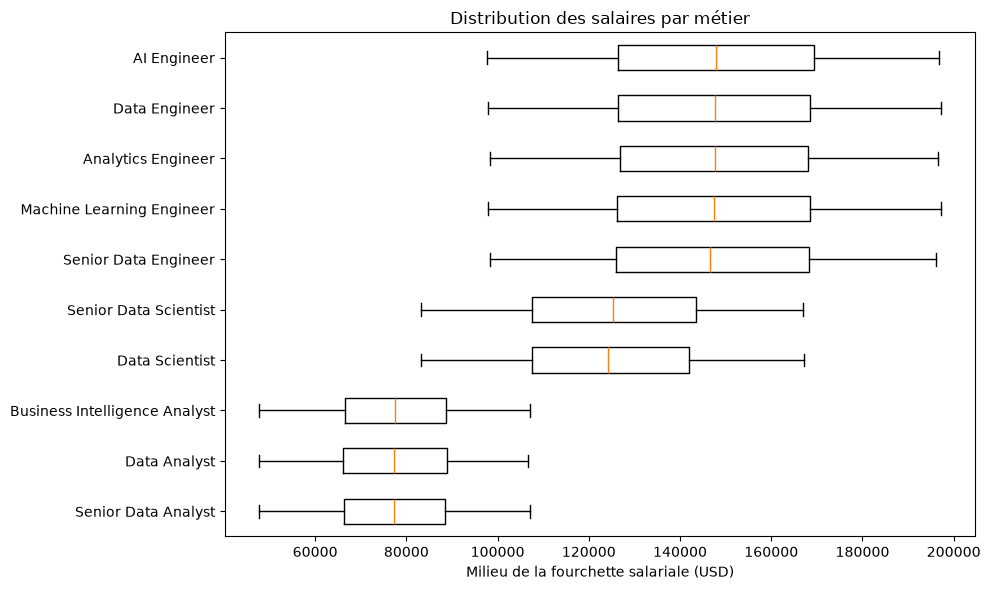

In [38]:
def bilan_salaire(groupes):
    return offres.groupby(groupes).agg(
        nombre_offres=("job_id", "nunique"),
        moyenne_usd=("salary_mid_usd", "mean"),
        q1_usd=("salary_mid_usd", lambda s: s.quantile(0.25)),
        mediane_usd=("salary_mid_usd", "median"),
        q3_usd=("salary_mid_usd", lambda s: s.quantile(0.75)),
        ecart_type_usd=("salary_mid_usd", "std"))

for dimension in ["job_title", "experience_level", "country"]:
    print(dimension)
    display(bilan_salaire(dimension).sort_values("mediane_usd").round(0))

salaires_croises = bilan_salaire(["job_title", "experience_level", "country"])
salaires_retenus = salaires_croises.loc[salaires_croises.nombre_offres.ge(30)]
print(f"Groupes croisés conservés : {len(salaires_retenus)} / {len(salaires_croises)} ; seuil = 30 offres.")
print(f"Plus petit groupe croisé : {salaires_croises.nombre_offres.min()} offres.")

# Part de la variation des salaires expliquée par chaque variable prise seule (rapport de corrélation η²)
variance_totale = offres.salary_mid_usd.var(ddof=0)
eta2 = {v: offres.groupby(v).salary_mid_usd.transform("mean").var(ddof=0) / variance_totale
        for v in ["job_title", "experience_level", "country", "remote_option", "employment_type"]}
display(pd.Series(eta2, name="part_variance_expliquee_pct").mul(100).sort_values(ascending=False).round(2).to_frame())

ordre = offres.groupby("job_title").salary_mid_usd.median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot([offres.loc[offres.job_title.eq(m), "salary_mid_usd"] for m in ordre], orientation="horizontal")
ax.set_yticks(range(1, len(ordre) + 1), ordre)
ax.set_title("Distribution des salaires par métier")
ax.set_xlabel("Milieu de la fourchette salariale (USD)")
plt.tight_layout()
plt.show()

**Lecture.**
- **Par métier**, les salaires forment trois niveaux très nets :
  - les métiers *Analyst* (Data Analyst, Senior Data Analyst, BI Analyst) : médiane ≈ **77 300 USD**, Q1–Q3 ≈ 66 000–88 800 ;
  - les *Data Scientist* (junior ou senior) : médiane ≈ **124 000–125 000 USD** ;
  - les métiers *Engineer* (Data, Senior Data, ML, Analytics, AI) : médiane ≈ **147 000–148 000 USD**, Q1–Q3 ≈ 126 000–169 000.
- **Par expérience**, les médianes vont de 122 600 à 123 300 USD : moins de 1 % d'écart entre les niveaux.
- **Par pays**, les médianes vont de 121 600 (Australie) à 124 300 USD (États-Unis) : environ 2 % d'écart seulement.
- La moyenne et la médiane sont très proches dans chaque groupe : les distributions sont symétriques, sans valeurs extrêmes qui fausseraient la moyenne.

Le calcul de η² résume ce constat : **le métier explique 67 % de la variation des salaires, le pays 0,02 %, l'expérience, le mode de travail et le contrat environ 0 %**.

Un point surprenant : un *Senior* Data Analyst a la même médiane qu'un Data Analyst (77 274 contre 77 289 USD). Sur un vrai marché, l'expérience et le pays ont un effet fort sur le salaire ; leur absence d'effet ici est une limite importante du dataset.

## Coefficients de corrélation

Un coefficient de corrélation mesure la force du lien entre deux variables, de 0 (aucun lien) à 1 (lien parfait). Le bon coefficient dépend du **type des variables** :

| Variables comparées | Coefficient | Exemple |
|---|---|---|
| numérique × numérique | **Pearson** (lien linéaire) et **Spearman** (lien monotone, basé sur les rangs) | salaire × nombre de candidats |
| catégorielle × numérique | **η (eta)**, racine du η² calculé plus haut | métier × salaire |
| catégorielle × catégorielle | **V de Cramér**, basé sur le chi² | expérience × mode de travail |
| binaire (0/1) × numérique | **point-bisériel** (Pearson appliqué à une variable 0/1) | compétence demandée × salaire |

On ne peut pas calculer un Pearson directement sur `job_title` ou `country` : ce sont des catégories, pas des nombres.

Pour lire les valeurs, on utilise l'ordre de grandeur habituel : moins de 0,1, lien négligeable ; 0,1 à 0,3, faible ; 0,3 à 0,5, moyen ; plus de 0,5, fort.

Corrélation de Pearson


,salary_min_usd,salary_max_usd,salary_mid_usd,applicants_estimate
salary_min_usd,1.000,0.973,0.993,-0.007
salary_max_usd,0.973,1.000,0.993,-0.007
salary_mid_usd,0.993,0.993,1.000,-0.007
applicants_estimate,-0.007,-0.007,-0.007,1.000


Corrélation de Spearman


,salary_min_usd,salary_max_usd,salary_mid_usd,applicants_estimate
salary_min_usd,1.000,0.975,0.993,-0.007
salary_max_usd,0.975,1.000,0.994,-0.007
salary_mid_usd,0.993,0.994,1.000,-0.007
applicants_estimate,-0.007,-0.007,-0.007,1.000


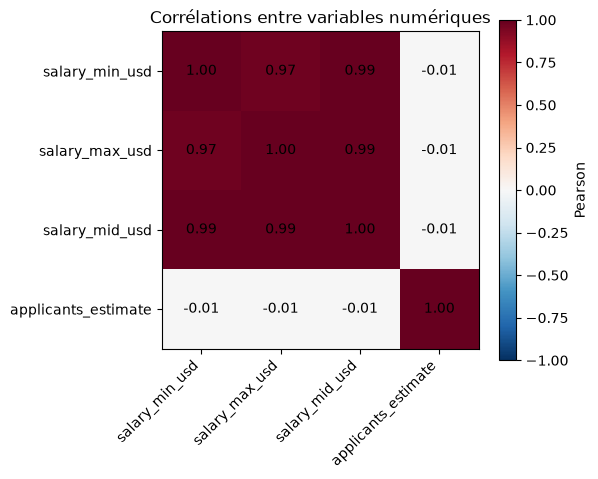

V de Cramér entre variables catégorielles


,job_title,experience_level,country,remote_option,employment_type
job_title,1.000,0.014,0.014,0.016,0.015
experience_level,0.014,1.000,0.013,0.003,0.005
country,0.014,0.013,1.000,0.015,0.016
remote_option,0.016,0.003,0.015,1.000,0.008
employment_type,0.015,0.005,0.016,0.008,1.000


Force du lien avec le salaire (valeur absolue)


,coefficient
job_title (η),0.820
country (η),0.013
compétence la plus liée (point-bisériel),0.011
applicants_estimate (Pearson),0.007
employment_type (η),0.006
remote_option (η),0.005
experience_level (η),0.003


Point-bisériel compétence × salaire, valeurs extrêmes :


,correlation
skill,
Snowflake,-0.006
Deep Learning,-0.005
Data Engineering,-0.005
Azure,0.009
Data Visualization,0.010
NLP,0.011


Plus forte corrélation entre deux compétences : 0.037


In [39]:
import numpy as np

# 1. Numérique × numérique : Pearson et Spearman
variables_numeriques = ["salary_min_usd", "salary_max_usd", "salary_mid_usd", "applicants_estimate"]
for methode in ["pearson", "spearman"]:
    print(f"Corrélation de {methode.capitalize()}")
    display(offres[variables_numeriques].corr(method=methode).round(3))

fig, ax = plt.subplots(figsize=(6, 5))
matrice = offres[variables_numeriques].corr()
image = ax.imshow(matrice, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(variables_numeriques)), variables_numeriques, rotation=45, ha="right")
ax.set_yticks(range(len(variables_numeriques)), variables_numeriques)
for (ligne, colonne), valeur in np.ndenumerate(matrice.to_numpy()):
    ax.text(colonne, ligne, f"{valeur:.2f}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="Pearson")
ax.set_title("Corrélations entre variables numériques")
plt.tight_layout()
plt.show()

# 2. Catégorielle × catégorielle : V de Cramér
def v_cramer(a, b):
    tableau = pd.crosstab(a, b)
    chi2 = chi2_contingency(tableau)[0]
    return np.sqrt(chi2 / (tableau.to_numpy().sum() * (min(tableau.shape) - 1)))

variables_categorielles = ["job_title", "experience_level", "country", "remote_option", "employment_type"]
cramer = pd.DataFrame({a: {b: v_cramer(offres[a], offres[b]) for b in variables_categorielles}
                       for a in variables_categorielles})
print("V de Cramér entre variables catégorielles")
display(cramer.round(3))

# 3. Lien de chaque variable avec le salaire
def eta(categorie, valeur):
    moyennes = valeur.groupby(categorie).transform("mean")
    return np.sqrt(moyennes.var(ddof=0) / valeur.var(ddof=0))

lien_salaire = {f"{v} (η)": eta(offres[v], offres.salary_mid_usd) for v in variables_categorielles}
lien_salaire["applicants_estimate (Pearson)"] = abs(offres.applicants_estimate.corr(offres.salary_mid_usd))

presence = (pd.crosstab(competences_offres.job_id, competences_offres.skill).clip(upper=1)
            .reindex(offres.job_id, fill_value=0))
point_biseriel = presence.corrwith(offres.set_index("job_id").salary_mid_usd)
lien_salaire["compétence la plus liée (point-bisériel)"] = point_biseriel.abs().max()

print("Force du lien avec le salaire (valeur absolue)")
display(pd.Series(lien_salaire, name="coefficient").sort_values(ascending=False).round(3).to_frame())
print("Point-bisériel compétence × salaire, valeurs extrêmes :")
display(point_biseriel.sort_values().iloc[[0, 1, 2, -3, -2, -1]].round(3).to_frame("correlation"))

# 4. Compétences entre elles (Pearson sur les variables 0/1, appelé coefficient phi)
phi = presence.corr().where(~np.eye(presence.shape[1], dtype=bool))
print(f"Plus forte corrélation entre deux compétences : {phi.abs().max().max():.3f}")

**Lecture.**
- **Variables numériques** : `salary_min_usd` et `salary_max_usd` sont très fortement corrélés (Pearson ≈ 0,97) : une offre avec un minimum élevé a aussi un maximum élevé, ce qui est logique. Le nombre de candidats n'est **pas lié** au salaire (≈ −0,01). Pearson et Spearman donnent les mêmes valeurs, donc les liens sont bien linéaires.
- **Variables catégorielles entre elles** : tous les V de Cramér sont inférieurs à 0,02. Le métier, l'expérience, le pays, le mode de travail et le contrat sont **indépendants les uns des autres** : par exemple, un poste Senior n'est pas plus souvent en télétravail. Cela confirme les tests du chi² précédents.
- **Lien avec le salaire** : le **métier** a un lien très fort (η ≈ 0,82). Toutes les autres variables sont négligeables : pays, expérience, mode, contrat, nombre de candidats, et chaque compétence (point-bisériel inférieur à 0,02 en valeur absolue).
- **Compétences entre elles** : la plus forte corrélation entre deux compétences est d'environ 0,04. Aucune compétence n'est associée à une autre, ce qui confirme les lifts de la partie « Compétences demandées ensemble ».

Conclusion : les coefficients résument toute l'EDA en un seul tableau. **Une seule relation forte existe dans le fichier, entre le métier et le salaire**. C'est aussi pourquoi le modèle de prédiction n'apprend rien d'autre que le métier.

Attention : une corrélation mesure un lien, pas une cause. Et une corrélation proche de 0 avec Pearson signifie seulement l'absence de lien *linéaire*.

## Pourquoi cibler Data Analyst ?

JobMatch vise à aider un utilisateur, en particulier un **étudiant ou un profil débutant**, à identifier des offres et les compétences à développer. Le choix de Data Analyst s'appuie sur trois éléments tirés des données :

1. **Un volume suffisant** : 5 506 offres (10 % du fichier), réparties de façon équilibrée sur les 4 niveaux d'expérience (environ 1 350 à 1 400 offres chacun). On peut donc comparer les niveaux sans travailler sur de petits groupes.
2. **Un métier d'entrée** : avec une médiane d'environ 77 300 USD, Data Analyst appartient à la famille de métiers aux salaires les plus bas du fichier (les métiers *Engineer* sont autour de 147 000 USD). C'est typiquement le premier poste visé par un profil débutant.
3. **Des résultats valables pour sa famille** : le tableau ci-dessous montre que Data Analyst et Business Intelligence Analyst ont presque le même salaire (médianes 77 289 et 77 470 USD) et les mêmes compétences (écarts d'environ 1 point au plus). Les conclusions sur Data Analyst valent donc aussi pour BI Analyst.

**Pourquoi pas Business Analyst ?** Ce métier est **absent du fichier** : on ne peut donc ni le choisir ni le comparer avec ces données. Business Intelligence Analyst est un intitulé distinct ; il sert de comparaison disponible, mais ne remplace pas une vraie comparaison Data Analyst / Business Analyst, qui demanderait des données supplémentaires.

In [40]:
metiers_comparaison = ["Data Analyst", "Business Intelligence Analyst"]
comparaison_metiers = offres.loc[offres.job_title.isin(metiers_comparaison)]
display(bilan_salaire("job_title").reindex(metiers_comparaison).round(2))
poids_metiers = offres.job_title.value_counts().reindex(metiers_comparaison).to_frame("nombre_offres")
poids_metiers["part_dataset_pct"] = poids_metiers.nombre_offres / len(offres) * 100
display(poids_metiers.round(2))
display(skill_prevalence(comparaison_metiers, competences_offres, "job_title").T.round(2))
display(group_percentages(comparaison_metiers, ["job_title"], "experience_level").set_index(["job_title", "experience_level"]).round(2))
print("Business Analyst présent :", offres.job_title.eq("Business Analyst").any())

,nombre_offres,moyenne_usd,q1_usd,mediane_usd,q3_usd,ecart_type_usd
job_title,,,,,,
Data Analyst,5506,77456.19,66051.0,77288.75,88853.75,13724.66
Business Intelligence Analyst,5651,77618.92,66533.0,77469.50,88623.75,13612.78


,nombre_offres,part_dataset_pct
job_title,,
Data Analyst,5506,10.01
Business Intelligence Analyst,5651,10.27


job_title,Business Intelligence Analyst,Data Analyst
skill,,
AWS,17.15,17.38
Airflow,17.29,17.18
Azure,16.39,16.60
BigQuery,17.71,17.56
Data Engineering,18.44,17.51
Data Visualization,17.04,17.51
Deep Learning,18.35,17.40
ETL,17.32,17.42
Excel,17.36,16.87


nombre_offres  \
job_title                     experience_level                  
Business Intelligence Analyst Entry                      1378   
                              Lead                       1415   
                              Mid                        1346   
                              Senior                     1512   
Data Analyst                  Entry                      1401   
                              Lead                       1364   
                              Mid                        1389   
                              Senior                     1352   

                                                effectif_groupe  pourcentage  
job_title                     experience_level                                
Business Intelligence Analyst Entry                        5651        24.39  
                              Lead                         5651        25.04  
                              Mid                          5651        23.82  
                              Senior                       5651        26.76  
Data Analyst                  Entry                        5506        25.44  
                              Lead                         5506        24.77  
                              Mid                          5506        25.23  
                              Senior                       5506        24.56

Business Analyst présent : False


## Synthèse et prolongement prédictif

L'expérience de prédiction est dans `04_data_science.ipynb` et son évaluation dans `05_model_evaluation.ipynb`. Elle prédit le milieu de la fourchette salariale. Elle compare une régression Ridge à deux références calculées sur l'ensemble d'entraînement seulement : la moyenne globale, et la moyenne de chaque métier. Les salaires minimum et maximum ne sont jamais utilisés comme variables explicatives.

## Résultats des comparaisons complémentaires

- **Salaires** : le métier est la seule variable qui fait varier le salaire (67 % de la variation expliquée). On distingue trois niveaux de médiane : environ 77 000 USD (Analyst), 125 000 USD (Data Scientist) et 147 000 USD (Engineer). L'expérience et le pays ont un effet quasi nul (moins de 2 % d'écart entre médianes).
- **Corrélations** : seul le lien métier × salaire est fort (η ≈ 0,82). Toutes les autres paires de variables ont un coefficient inférieur à 0,02 (Pearson, V de Cramér, point-bisériel).
- **Expérience** : les quatre niveaux représentent chacun environ 25 % des offres. Toutes les comparaisons sont faites en pourcentage de l'effectif de chaque groupe.
- **Mode de travail** : présentiel, hybride et télétravail représentent entre 30,5 % et 36,9 % des offres dans chaque groupe métier × expérience. Pas de lien avec l'expérience (chi², p ≈ 0,99). Le lien avec le métier est à la limite du seuil (p ≈ 0,045), avec des écarts de quelques points seulement.
- **Compétences ensemble** : BigQuery + SQL est la paire la plus fréquente (1 527 offres, 2,78 %), mais toutes les paires ont un lift inférieur à 1. Aucune combinaison de compétences n'est surreprésentée.
- **Familles de compétences** : en regroupant les 26 compétences en 9 familles (outils proches ou concurrents comme Tableau et Power BI), aucune association n'apparaît non plus (lifts entre 0,86 et 0,93).
- **Compétences selon le métier** : chaque famille est demandée dans la même proportion d'offres quel que soit le métier (écart au plus de 3 points, aucun chi² significatif). Un Data Analyst se voit demander du Machine Learning / IA autant qu'un AI Engineer (63 % contre 64 %). On ne peut donc pas recommander de compétences propres à un métier avec ce fichier.
- **Junior / Senior** : l'écart maximal Entry/Senior est de 0,97 point tous métiers confondus et de 3,83 points au sein de Data Analyst (Airflow). Après correction pour tests multiples, aucun écart n'est significatif : les compétences demandées n'évoluent pas avec l'expérience dans ce fichier.
- **Pays** : les 13 pays sont conservés. Leur poids dans la collecte (7,5 % à 8 % chacun) ne mesure pas leur poids dans le marché réel.
- **Data Analyst** : 5 506 offres (10,01 %). Choisi comme métier d'entrée pour un profil débutant ; Business Analyst est absent du fichier.

**Limite principale.** Les répartitions sont presque parfaitement uniformes (≈ 25 % par niveau, ≈ 33 % par mode, ≈ 7,7 % par pays, compétences attribuées sans association et identiques pour tous les métiers), et un Senior Data Analyst gagne autant qu'un Data Analyst. Ces signes suggèrent des **données générées artificiellement** plutôt que collectées sur de vraies offres. Nos conclusions décrivent donc ce fichier ; elles ne doivent pas être présentées comme des vérités sur le marché réel de l'emploi.